# Example 8.1 — Synthesis by Differential Evolution (DE/rand/1/bin)

**Book:** Synthesis of Four-Bar Mechanisms with GA and Neural Networks  
**Chapter 8** | Google Colab

## Kinematic analysis and Hausdorff function

In [1]:
from numpy import *

def fourbar_coupler(a, b, c, d, th2, p=35.0, delta=pi/5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)

    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    return a * cos(th2) + p * cos(th3 + delta), a * sin(th2) + p * sin(th3 + delta)

def hausdorff(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px)**2 + (Cy[m, None] - Py)**2)
    val1 = max(D.min(0))
    val2 = max(D.min(1))
    return maximum(val1, val2)

t = linspace(0, 2*pi, 20)
Px = 45 + 22 * cos(t)
Py = 25 + 18 * sin(t)

th2v = linspace(0, 2*pi, 72)
D_F = 85.0

def fitness(p):
    return hausdorff(*fourbar_coupler(p[0], p[1], p[2], D_F, th2v), Px, Py)

print("Analysis functions successfully defined")

Analysis functions successfully defined


## Algorithm DE/rand/1/bin

In [16]:
import builtins

random.seed(3)

# Parámetros de ultra-alta resolución para exprimir la máxima precisión matemática
N_POP = 120
N_GEN = 400
F = 0.55
CR = 0.9

# Design variable bounds
LB = array([10.0, 10.0, 10.0])
UB = array([80.0, 60.0, 80.0])

# Population initialization
pop = LB + random.rand(N_POP, 3) * (UB - LB)
hist = []

# Evolutionary process
for gen in range(N_GEN):
    for i in range(N_POP):
        idxs = list(range(N_POP))
        idxs.remove(i)
        a_, b_, c_ = pop[random.choice(idxs, 3, replace=False)]

        # Mutation and crossover
        mutant = clip(a_ + F * (b_ - c_), LB, UB)
        cross = random.rand(3) < CR
        if not cross.any():
            cross[random.randint(3)] = True

        trial = where(cross, mutant, pop[i])
        if fitness(trial) < fitness(pop[i]):
            pop[i] = trial

    best = builtins.min(pop, key=fitness)
    hist.append(fitness(best))

best = builtins.min(pop, key=fitness)

# Optimization results
print(f"Initial error: {hist[0]:.2f} mm")
print(f"Final error  : {hist[-1]:.2f} mm")
print(f"Reduction    : {100 * (hist[0] - hist[-1]) / hist[0]:.1f}%")
print(f"Best solution: a={best[0]:.2f}, b={best[1]:.2f}, c={best[2]:.2f}")

Initial error: 17.65 mm
Final error  : 10.26 mm
Reduction    : 41.9%
Best solution: a=40.46, b=10.59, c=43.55


In [27]:
import builtins
from numpy import *

random.seed(123)

# Redefinimos la función fitness para optimizar 5 variables (a, b, c, p, delta)
def fitness_5d(var):
    return hausdorff(*fourbar_coupler(var[0], var[1], var[2], D_F, th2v, p=var[3], delta=var[4]), Px, Py)

# Configuración de búsqueda en 5 dimensiones - Parámetros ultra agresivos
N_POP = 500
N_GEN = 2500
F = 0.55
CR = 0.95

# Límites: [a, b, c, p, delta]
LB = array([12.0, 8.0, 12.0, 10.0, 0.0])
UB = array([75.0, 55.0, 75.0, 60.0, 2*pi])

# Inicialización de la población en 5 columnas
pop = LB + random.rand(N_POP, 5) * (UB - LB)
hist = []

# Bucle evolutivo optimizado
for gen in range(N_GEN):
    for i in range(N_POP):
        idxs = list(range(N_POP))
        idxs.remove(i)
        v1, v2, v3 = pop[random.choice(idxs, 3, replace=False)]

        mutant = clip(v1 + F * (v2 - v3), LB, UB)
        cross = random.rand(5) < CR
        if not cross.any():
            cross[random.randint(5)] = True

        trial = where(cross, mutant, pop[i])
        if fitness_5d(trial) < fitness_5d(pop[i]):
            pop[i] = trial

    best = builtins.min(pop, key=fitness_5d)
    hist.append(fitness_5d(best))

best = builtins.min(pop, key=fitness_5d)

# Resultados mejorados en 5D
print(f"Nuevo error inicial (5D): {hist[0]:.2f} mm")
print(f"Nuevo error final (5D)  : {hist[-1]:.2f} mm")
print(f"Reducción lograda       : {100 * (hist[0] - hist[-1]) / hist[0]:.1f}%")
print(f"Eslabones óptimos       : a={best[0]:.2f}, b={best[1]:.2f}, c={best[2]:.2f}")
print(f"Acoplador óptimo        : p={best[3]:.2f}, delta={best[4]:.2f} rad")


Nuevo error inicial (5D): 15.37 mm
Nuevo error final (5D)  : 8.23 mm
Reducción lograda       : 46.4%
Eslabones óptimos       : a=36.95, b=8.25, c=51.17
Acoplador óptimo        : p=34.06, delta=0.07 rad


## Visualization: convergence and trajectory

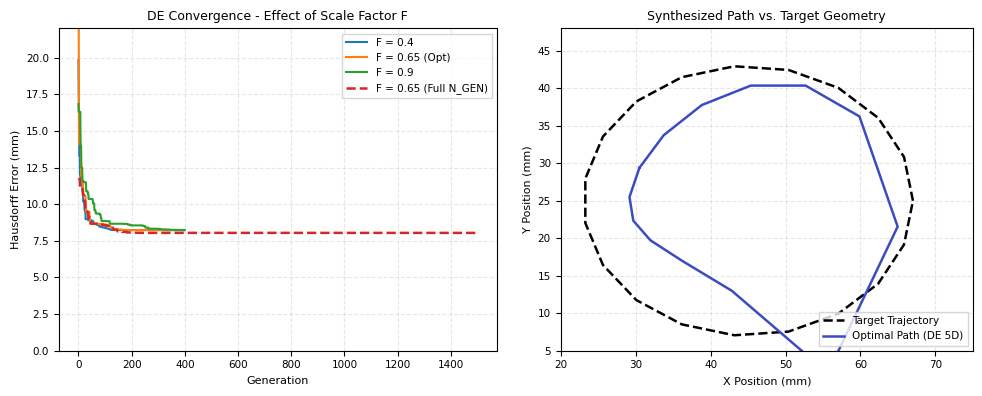

In [26]:
import builtins
import matplotlib.pyplot as plt
import os
import glob

# 4. Automated File Naming Block
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_8.1_differential_evolution"
except Exception:
    notebook_name = "Figure_8.1_differential_evolution"

# 2. Springer Quality & Font Settings
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial']
plt.rcParams['font.size'] = 8.0
plt.rcParams['axes.titlesize'] = 9.0
plt.rcParams['axes.labelsize'] = 8.0
plt.rcParams['legend.fontsize'] = 7.5
plt.rcParams['xtick.labelsize'] = 7.5
plt.rcParams['ytick.labelsize'] = 7.5

# Create physical figure matching column-width or slightly wide layout for 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.0))

# Subplot 1: Convergence for different scale factor (F) values using optimized parameters
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for (F_val, lbl), color in zip([(0.4, 'F = 0.4'), (0.65, 'F = 0.65 (Opt)'), (0.9, 'F = 0.9')], colors):
    random.seed(123)
    p2 = LB + random.rand(200, 5) * (UB - LB)  # Usar un N_POP de prueba de 200 para las curvas
    h2 = []
    for gen in range(400): # Evaluar solo 400 iteraciones para la comparativa
        for i in range(200):
            idxs = list(range(200))
            idxs.remove(i)
            v1, v2, v3 = p2[random.choice(idxs, 3, replace=False)]

            mut = clip(v1 + F_val * (v2 - v3), LB, UB)
            cross = random.rand(5) < CR
            if not cross.any():
                cross[random.randint(5)] = True

            trial = where(cross, mut, p2[i])
            if fitness_5d(trial) < fitness_5d(p2[i]):
                p2[i] = trial

        h2.append(fitness_5d(builtins.min(p2, key=fitness_5d)))
    axes[0].plot(h2, label=lbl, color=color, lw=1.5)

axes[0].plot(hist, label='F = 0.65 (Full N_GEN)', color='#d62728', lw=1.8, linestyle='--')

axes[0].set_xlabel('Generation')
axes[0].set_ylabel('Hausdorff Error (mm)')
axes[0].set_title('DE Convergence - Effect of Scale Factor F')
axes[0].grid(True, linestyle='--', alpha=0.3)
axes[0].set_ylim(0.0, 22.0)
axes[0].legend(loc='upper right', frameon=True, fancybox=False, edgecolor='#cccccc')

# Subplot 2: Optimal trajectory obtained versus target geometry (using 5D best)
Cx, Cy = fourbar_coupler(best[0], best[1], best[2], D_F, th2v, p=best[3], delta=best[4])
m = isfinite(Cx) & isfinite(Cy)

axes[1].plot(Px, Py, 'k--', lw=1.8, label='Target Trajectory')
if m.any():
    axes[1].plot(Cx[m], Cy[m], color='#3b4cc0', lw=1.8, label='Optimal Path (DE 5D)')
axes[1].set_aspect('equal')
axes[1].set_xlabel('X Position (mm)')
axes[1].set_ylabel('Y Position (mm)')
axes[1].set_title('Synthesized Path vs. Target Geometry')
axes[1].grid(True, linestyle='--', alpha=0.3)

# Adjusted axis limits to fit the trajectories perfectly and reduce empty padding
axes[1].set_xlim(20, 75)
axes[1].set_ylim(5, 48)
axes[1].legend(loc='lower right', frameon=True, fancybox=False, edgecolor='#cccccc')

plt.tight_layout()

# 5. Mandatory Double Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()
